<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/21_QKD_Attack_Detection/HybridQNN_CVQKDAttackDetection_He2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid CNN + variational quantum circuit (HQCNN) for CV-QKD hacking-attack detection: He et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Xinglin He, Jiaxun Xiao and Xuanli Lyu, "A Hybrid Quantum-Classical Neural Network Framework for the Detection of Quantum
> Hacking Attacks in CVQKD", *Applied Sciences* 16(6), 2793 (2026). https://doi.org/10.3390/app16062793

The authors' data are not available ("part of an ongoing study"), and no code is published. The notebook therefore
**simulates the CV-QKD receiver itself** from the physical model that the paper describes (Gaussian modulation, lossy
Gaussian channel, homodyne detection, the four attacks of Sec. 3.2) and then builds the paper's pipeline on top of it.

**The problem in plain words.** In continuous-variable quantum key distribution (CVQKD) Alice sends laser pulses whose
amplitude is random (Gaussian) and Bob measures them with a homodyne detector. An eavesdropper can attack Bob's *equipment*
instead of the quantum channel: she can change the strength of the reference laser (local oscillator, **LOIA**), trick the
calibration of the shot-noise level (**calibration attack**), drive the detector into saturation (**saturation attack**), or
combine an intercept-resend attack with extra light pulses (**hybrid attack**). Each attack leaves a fingerprint in the
statistics of Bob's raw measurement results. The paper feeds a block of 10 000 raw pulses, reshaped to a 100 x 100 "image",
to a small convolutional network (CNN); a compressed 8-number summary becomes the rotation angles of 8 qubits; a
**variational quantum circuit (VQC)** with data re-uploading and `StronglyEntanglingLayers` then produces the class scores
(no attack / LOIA / calibration / saturation / hybrid).

**What the notebook does.**
1. Simulates the five-class CVQKD pulse-block dataset (the paper's dataset is private) and explores it.
2. Draws and checks the quantum circuit that is trained (PennyLane QNode versus the fast simulator used for training).
3. Trains the **HQCNN** (CNN + 8-qubit VQC), a **ResNet** baseline (the paper's comparison), a **CNN with a classical
   head** of similar size (an ablation the paper does not run), and classical machine-learning models on hand-made block statistics.
4. Redraws the paper's Table 1, Fig. 3 (qubit scaling 4/6/8/10), Fig. 4 (confusion matrices), the parameter-count argument of
   Sec. 5.5, and ends with a verdict per claim, a critical reading and exercises.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane (PyTorch ships with Colab); if Colab asks to restart the session, do so and run all cells again. No GPU, no
IBM account and no download are needed: the data are generated inside the notebook. Three scales are available in the
configuration cell: `FAST_MODE = True` is a class demo (blocks of 900 pulses, a few epochs, about 8 minutes on a CPU);
`FAST_MODE = False` (the committed run) uses blocks of 2500 pulses and longer training (about 30 minutes on a shared 8-core
CPU); `PAPER_SCALE = True` uses the paper's own scale (Q = 10 000 pulses per block, 5000 blocks, 100 epochs), which takes many
hours on a CPU and was **not** run here.

**What you get at the end.** The HQCNN and its baselines compared on the same simulated data, the paper's numbers next to ours
with an explicit verdict per claim, and an honest answer to "what did we reproduce, and on which data?".

## The paper in one page

**Problem.** Five-class detection of quantum hacking attacks on a GMCS-CVQKD receiver: no attack (NA), local-oscillator
intensity attack (LOIA, "LA"), calibration attack (CA), saturation attack (SA), hybrid attack (HA).

**Data (Sec. 5.1).** Generated from the CVQKD physical model of Fig. 1: for each of the 5 scenarios N = 10^7 valid pulses are
sampled and cut into blocks of Q = 10 000 pulses, so every class has 1000 blocks and the dataset 5000 blocks; split 4 : 1
(4000 train, 1000 test). Attack parameters are "fixed representative values" taken from Mao et al. 2020 and Du et al. 2022
(not listed in the paper).

**Attack models (Sec. 3.2).** LOIA: local-oscillator power scaled by k (0 < k < 1), variance
V = kT(V_A + xi)N0 + kN0 + V_el (Eq. 2). Calibration: Bob normalises with a tampered shot-noise value alpha N0 (Eqs. 4, 5).
Saturation: the detector output is clipped at +-X_sat (Eq. 6). Hybrid: full intercept-resend (excess noise 2 N0) plus extra
light pulses that add a DC offset D_ext and excess noise xi_ext, driving the detector towards saturation (Eqs. 8, 9).

**Model (Sec. 4).** Each block is reshaped to a sqrt(Q) x sqrt(Q) map and normalised to [0, 1]; four 3x3 convolution layers
with 32, 64, 128, 256 channels and ReLU extract a feature vector (d = 32 in Sec. 5.5); a linear "transition" layer compresses it
to n values and a Tanh bounds them to [-1, 1]; these are scaled to [-pi, pi] and used as RY angles on n qubits. The VQC repeats
(RY data encoding, then one `StronglyEntanglingLayers` layer) four times (**data re-uploading**, 4 x n x 3 = 96 trainable
parameters for n = 8), measures Pauli-Z on every qubit, and a linear layer turns the n expectation values into 5 logits
(softmax, cross-entropy). Adam, learning rate 1e-4 for the CNN and 1e-3 for the quantum layers, 100 epochs.

**Claims to check.**
1. Overall test accuracy of the HQCNN 0.93; ResNet 0.87 ("6 % better", Table 1 / abstract).
2. Calibration, saturation and hybrid attacks are classified perfectly (recall and F1 = 1.00) by both models.
3. The only errors are between NA and LOIA; LOIA recall 0.90 (HQCNN) versus 0.66 (ResNet) in the text (Table 1 as extracted is garbled, see below).
4. Qubit scaling (Fig. 3): 8 qubits is best of {4, 6, 8, 10}; 4 and 6 qubits still exceed 90 % accuracy; 10 qubits is no better than 6.
5. Parameter efficiency (Sec. 5.5): the VQC has 96 parameters versus about 21 000 for an equivalent MLP; the HQCNN has fewer
   parameters than the ResNet.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Private ("part of an ongoing study"), 5 x 1000 blocks of Q = 10 000 pulses | **Physics-based simulator written here** (Gaussian modulation, channel, homodyne detector, 4 attacks). Attack strengths are our choice (`# CHOICE:`); block count and Q are set in the configuration cell (`FAST_MODE` uses short blocks) |
| Channel / detector values | not given | V_A = 4 SNU, T = 0.25, xi = 0.05 SNU, electronic noise 0.1 SNU, shot-noise unit N0 = 1 |
| LOIA strength k | "fixed representative value" | k = 0.97, i.e. 3 % less local-oscillator power (a subtle attack). A block of Q pulses estimates its variance with relative error sqrt(2/Q), so this attack is separated from NA by (1 - k) sqrt(Q/2) ~ 2 standard errors at the paper's Q = 10 000 (best possible variance-based NA-versus-LOIA decision about 84 % correct) but only ~1 at Q = 2500 and ~0.6 at Q = 900: **the smaller blocks used here make NA-versus-LOIA harder than in the paper** (the ceiling is measured below) |
| Calibration bias alpha | not given | alpha = 1.15; Bob's data are divided by sqrt(alpha) (our reading of Eq. 5, whose extracted form is ambiguous) |
| Saturation level | not given | X_sat = 2 sigma_0 (sigma_0 = std of an unattacked pulse) |
| Hybrid attack | IR (2 N0) + extra pulses (offset D_ext, noise xi_ext) | xi_IR = 2, xi_ext = 0.1, D_ext = 1.5 SNU, clipping at +-2.75 sigma_0 |
| Block normalisation | "map the amplitude distribution to [0, 1]" | one global min-max (limits taken from the training split only); a per-block min-max would erase the scale information that LOIA and CA change |
| Split | 4 : 1 | 4 : 1 stratified, plus 15 % of the training part held out to choose the epoch (the paper chooses the epoch on the **test** set) |
| CNN | 4 conv layers 32/64/128/256, 3x3, ReLU; resolution reduced | stride-2 3x3 convolutions (that is how the resolution is reduced), + BatchNorm, global mean **and** max pooling, Linear(512 -> 32) = the d = 32 feature vector. BatchNorm and the max pooling are our additions: without them the network did not learn in a pilot |
| Transition | Linear to n, Tanh, scaled to [-pi, pi] | exactly that |
| VQC | 8 qubits, 4 re-uploading layers, `StronglyEntanglingLayers`, Pauli-Z read-out, 96 parameters | the same; layer l uses CNOT range (l mod (n-1)) + 1 as inside one 4-layer `StronglyEntanglingLayers`; initial angles uniform in [0, 2 pi) |
| Post-quantum layer | linear to 5 logits, softmax | Linear(n -> 5) |
| ResNet baseline | "ResNet [36]" with the same feature-extraction depth | 4 residual blocks (32/64/128/256 channels, BatchNorm, stride 2), global average pooling, Linear(256 -> 5) |
| Optimiser | Adam; lr 1e-4 CNN / 1e-3 VQC; 100 epochs | Adam with two parameter groups and a cosine decay of both learning rates to 0; learning rates and epochs in the configuration cell (larger rates and far fewer epochs than the paper because of the CPU budget) |
| Batch size | not given | 16 |
| Training augmentation | none mentioned | the 10^4 pulses of a training block are i.i.d., so their order is irrelevant: each time a training block is used its pulses are randomly permuted (labels and statistics unchanged). It stops the network from memorising pixel noise. Never applied to validation or test data |
| Model selection | "Best Model Saving" on the test set (leaks the test set) | epoch with the best **validation** accuracy; the paper's best-test-epoch number is shown as a second, optimistic figure |
| Simulator | PyTorch/PennyLane (implied by "Strongly Entangling Layers", "Angle Embedding") | PennyLane QNode (`default.qubit`) for drawing and checking; an equivalent batched PyTorch state-vector code (checked against the QNode, values and gradients) for training speed |
| Hardware | none | none |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False       # True: class demo (short blocks, few epochs). False: Q = 10 000 pulses per block as in the paper, longer training.
SEED      = 42              # master seed (data, split, initial weights, batches)
IBM_TOKEN = ""              # unused: the paper needs no quantum hardware
N_THREADS = 2               # PyTorch CPU threads

N_QUBITS   = 8              # paper: 8 qubits is the chosen model
VQC_LAYERS = 4              # paper: 4 re-uploading / variational layers
BATCH      = 16             # CHOICE: not given in the paper
TEST_SIZE  = 0.20           # paper: 4 : 1
VAL_FRACTION = 0.15         # CHOICE: part of the training data used to pick the epoch (the paper uses the test set)
LR_CLASSICAL, LR_QUANTUM = 2e-3, 1e-2      # paper: 1e-4 and 1e-3 for 100 epochs; larger because we train for far fewer epochs

PAPER_SCALE = False         # True: the paper's own scale (Q = 10 000, 1000 blocks per class, 100 epochs) - hours on a CPU, meant for a GPU/long session

if PAPER_SCALE:
    Q, BLOCKS_PER_CLASS, EPOCHS = 10000, 1000, 100            # 100 x 100 maps, 5000 blocks
    QUBIT_LIST, QUBIT_EPOCHS, MODEL_SEEDS = [4, 6, 8, 10], 100, [SEED]
    LR_CLASSICAL, LR_QUANTUM = 1e-4, 1e-3                      # the paper's learning rates
elif FAST_MODE:
    Q = 900                  # pulses per block (paper: 10 000) -> 30 x 30 map
    BLOCKS_PER_CLASS = 100    # paper: 1000
    EPOCHS = 10            # paper: 100
    QUBIT_LIST = [4, 8]      # paper: [4, 6, 8, 10]
    QUBIT_EPOCHS = 10
    MODEL_SEEDS = [SEED]
else:
    Q = 2500                 # 50 x 50 map (paper: 10 000), see the run-time note in the markdown above
    BLOCKS_PER_CLASS = 250
    EPOCHS = 30
    QUBIT_LIST = [4, 6, 8, 10]
    QUBIT_EPOCHS = 30
    MODEL_SEEDS = [SEED]
SIDE = int(round(Q ** 0.5))
DATA_DIR = "qkd_data"

In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy, pennylane as qml
from scipy.stats import skew, kurtosis
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, ConfusionMatrixDisplay

torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print(f"FAST_MODE = {FAST_MODE} | Q = {Q} pulses/block ({SIDE}x{SIDE}) | blocks/class = {BLOCKS_PER_CLASS} | epochs = {EPOCHS} | qubits tested = {QUBIT_LIST}")
T0 = time.time()

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | Q = 2500 pulses/block (50x50) | blocks/class = 250 | epochs = 30 | qubits tested = [4, 6, 8, 10]


## 1. The data: a simulated CVQKD receiver under attack

**Why a simulator.** The paper's dataset is "part of an ongoing study" and is not published, so we write down the physics of
Sec. 3 and sample from it, exactly as the paper says it did. All quantities are in shot-noise units (SNU, N0 = 1).

* Alice draws x ~ N(0, V_A). The Gaussian channel (transmittance T, excess noise xi) gives Bob
  `y = sqrt(T) x + z`, with `z ~ N(0, 1 + T xi)` (vacuum plus excess noise, Eq. 1), and Bob's detector adds electronic noise
  of variance V_el. An unattacked pulse therefore has variance `T V_A + 1 + T xi + V_el`.
* **LOIA** (Eqs. 2, 3): the local-oscillator power Bob receives is scaled by k, so the signal and shot noise scale by k but the
  electronic noise does not: `V = k (T V_A + 1 + T xi) + V_el`.
* **Calibration attack** (Eqs. 4, 5): Bob normalises with the tampered shot-noise value alpha N0, so his data are divided by
  sqrt(alpha): `V = (T V_A + 1 + T xi + V_el) / alpha`.
* **Saturation attack** (Eq. 6): the detector output is clipped at +-X_sat.
* **Hybrid attack** (Eqs. 8, 9): intercept-resend noise (xi_IR = 2) and extra light pulses (noise xi_ext, DC offset D_ext) that
  push the detector towards saturation: clipping of an *offset* distribution.

The pulses inside a block are independent, so the 100 x 100 "image" has no spatial structure beyond the statistics of the
pixel values. We come back to this in the critical reading.

In [4]:
CLASSES = ["NA", "LOIA", "CA", "SA", "HA"]
LONG = {"NA": "no attack", "LOIA": "local-oscillator intensity attack", "CA": "calibration attack", "SA": "saturation attack", "HA": "hybrid attack"}

# CHOICE: physical parameters of the simulated link and of the attacks (the paper gives none of them)
VA, T_CH, XI, V_EL = 4.0, 0.25, 0.05, 0.1            # modulation variance, transmittance, excess noise, electronic noise (SNU)
SIG0 = float(np.sqrt(T_CH * VA + 1 + T_CH * XI + V_EL))   # std of one unattacked pulse
K_LOIA = 0.97                                         # local-oscillator scaling (3 % less LO power: a subtle attack)
ALPHA = 1.15                                          # calibration bias
XSAT = 2.0 * SIG0                                     # saturation level of the saturation attack
XSAT_H, D_EXT, XI_IR, XI_EXT = 2.75 * SIG0, 1.5, 2.0, 0.1   # hybrid attack: clipping level, DC offset, intercept-resend noise, extra-pulse noise

def simulate_blocks(cls, nb, Q, rng):
    """nb blocks of Q homodyne results of class cls (float32, shape (nb, Q))."""
    x = np.sqrt(VA) * rng.standard_normal((nb, Q), dtype=np.float32)                         # Alice's Gaussian modulation
    xi = XI + (XI_IR + XI_EXT if cls == "HA" else 0.0)                                        # hybrid: total excess noise (Eq. 9)
    z = np.sqrt(1 + T_CH * xi) * rng.standard_normal((nb, Q), dtype=np.float32)               # vacuum + excess noise
    el = np.sqrt(V_EL) * rng.standard_normal((nb, Q), dtype=np.float32)                       # detector electronic noise
    sig = np.sqrt(T_CH) * x + z
    if cls == "LOIA":   y = np.sqrt(K_LOIA) * sig + el                                        # Eq. 2
    elif cls == "CA":   y = (sig + el) / np.sqrt(ALPHA)                                       # Eq. 5 (our reading)
    elif cls == "SA":   y = np.clip(sig + el, -XSAT, XSAT)                                    # Eq. 6
    elif cls == "HA":   y = np.clip(sig + el + D_EXT, -XSAT_H, XSAT_H)                        # Eq. 8: offset, detector driven into saturation
    else:               y = sig + el
    return y.astype(np.float32)

def make_dataset(nb, Q, seed):
    r = np.random.default_rng(seed)
    X = np.concatenate([simulate_blocks(c, nb, Q, r) for c in CLASSES]); y = np.repeat(np.arange(len(CLASSES)), nb)
    return X, y

t = time.time()
X_ALL, y_ALL = make_dataset(BLOCKS_PER_CLASS, Q, SEED)
print(f"simulated {len(y_ALL)} blocks of {Q} pulses in {time.time() - t:.1f} s; array {X_ALL.shape}, {X_ALL.nbytes / 1e6:.0f} MB")

# check the simulator against the closed-form variances of the paper's equations
v_na = T_CH * VA + 1 + T_CH * XI + V_EL
theory = {"NA": v_na, "LOIA": K_LOIA * (T_CH * VA + 1 + T_CH * XI) + V_EL, "CA": v_na / ALPHA}
rows = [{"class": c, "variance (simulated mean)": X_ALL[y_ALL == k].var(1).mean(), "variance (paper's formula)": theory.get(c, np.nan)} for k, c in enumerate(CLASSES)]
display(pd.DataFrame(rows).round(4))

simulated 1250 blocks of 2500 pulses in 0.4 s; array (1250, 2500), 12 MB


,class,variance (simulated mean),variance (paper's formula)
0,NA,2.1070,2.1125
1,LOIA,2.0499,2.0521
2,CA,1.8375,1.8370
3,SA,1.9422,NaN
4,HA,2.3623,NaN


## 2. Split and normalisation

As in the paper: a 4 : 1 stratified split of the 5 x N blocks. A further 15 % of the training part is held out as a
**validation set** that picks the epoch (the paper uses the test set for this, which leaks it; see the critical reading).
Pulse values are mapped to [0, 1] with one global min-max whose limits come from the **training blocks only**; test values
are clipped to [0, 1]. A *per-block* min-max would remove the overall scale of a block, which is exactly what LOIA and the
calibration attack change.

In [5]:
idx_all = np.arange(len(y_ALL))
idx_tr_full, idx_te = train_test_split(idx_all, test_size=TEST_SIZE, stratify=y_ALL, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_tr_full, test_size=VAL_FRACTION, stratify=y_ALL[idx_tr_full], random_state=SEED)
LO, HI = float(X_ALL[idx_tr].min()), float(X_ALL[idx_tr].max())          # fitted on the training blocks only

def to_tensor(idx):
    z = np.clip((X_ALL[idx] - LO) / (HI - LO), 0.0, 1.0)
    return torch.from_numpy(z.astype(np.float32)).reshape(-1, 1, SIDE, SIDE)
Xtr, Xva, Xte = to_tensor(idx_tr), to_tensor(idx_va), to_tensor(idx_te)
ytr, yva, yte = (torch.from_numpy(y_ALL[i]) for i in (idx_tr, idx_va, idx_te))
DATA = (Xtr, ytr, Xva, yva, Xte, yte)
print(f"train {tuple(Xtr.shape)} | validation {tuple(Xva.shape)} | test {tuple(Xte.shape)} | normalisation limits (SNU): [{LO:.2f}, {HI:.2f}]")

train (850, 1, 50, 50) | validation (150, 1, 50, 50) | test (250, 1, 50, 50) | normalisation limits (SNU): [-7.39, 7.75]


## Dataset Exploration and Visualisation

Every observation is one **block of Q simulated homodyne results** (a 1-D time series of pulses, reshaped to a SIDE x SIDE
map for the CNN). The cell below prints the shape, the feature names, the original class labels and counts, and a per-class
summary. The following cells plot the class distribution, example blocks and pulse histograms, and 2-D scatter plots of the
real (simulated) blocks coloured by their ground-truth class. A block has Q numbers, so for the scatter plots we use the two
projections that make sense for time-series windows: PCA of **window features** (mean, standard deviation, skewness, kurtosis,
min, max, 1 % and 99 % quantiles of the block) and PCA of the **raw pulses**; both are fitted on the training split only and
shown first as raw PCA coordinates and then scaled to [0, pi] (what an angle encoding would receive).

In [6]:
WIN_FEATURES = ["mean", "std", "skew", "kurtosis", "min", "max", "q01", "q99"]
def window_features(A):
    return np.c_[A.mean(1), A.std(1), skew(A, 1), kurtosis(A, 1), A.min(1), A.max(1), np.quantile(A, 0.01, 1), np.quantile(A, 0.99, 1)]

print(f"dataset shape: {X_ALL.shape}  (blocks x pulses per block);  as CNN input: ({len(y_ALL)}, 1, {SIDE}, {SIDE})")
print("raw features per block: the", Q, "normalised pulse values;  window features used for baselines/plots:", WIN_FEATURES)
print("original labels:", {k: LONG[k] for k in CLASSES})
print("class counts (all blocks):", dict(zip(CLASSES, np.bincount(y_ALL).tolist())))
print("train / validation / test counts per class:", np.bincount(ytr.numpy()).tolist(), np.bincount(yva.numpy()).tolist(), np.bincount(yte.numpy()).tolist())
F_ALL = window_features(X_ALL)
display(pd.DataFrame(F_ALL, columns=WIN_FEATURES).assign(label=[CLASSES[k] for k in y_ALL]).groupby("label").mean().loc[CLASSES].round(3))

dataset shape: (1250, 2500)  (blocks x pulses per block);  as CNN input: (1250, 1, 50, 50)
raw features per block: the 2500 normalised pulse values;  window features used for baselines/plots: ['mean', 'std', 'skew', 'kurtosis', 'min', 'max', 'q01', 'q99']
original labels: {'NA': 'no attack', 'LOIA': 'local-oscillator intensity attack', 'CA': 'calibration attack', 'SA': 'saturation attack', 'HA': 'hybrid attack'}
class counts (all blocks): {'NA': 250, 'LOIA': 250, 'CA': 250, 'SA': 250, 'HA': 250}
train / validation / test counts per class: [170, 170, 170, 170, 170] [30, 30, 30, 30, 30] [50, 50, 50, 50, 50]


,mean,std,skew,kurtosis,min,max,q01,q99
label,,,,,,,,
NA,-0.002,1.451,0.003,-0.003,-5.062,5.064,-3.358,3.376
LOIA,0.002,1.432,0.003,-0.007,-4.971,4.971,-3.325,3.327
CA,-0.003,1.355,0.002,-0.003,-4.717,4.738,-3.147,3.133
SA,0.002,1.394,-0.004,-0.542,-2.907,2.907,-2.907,2.907
HA,1.457,1.537,-0.276,-0.372,-3.875,3.997,-2.279,3.997


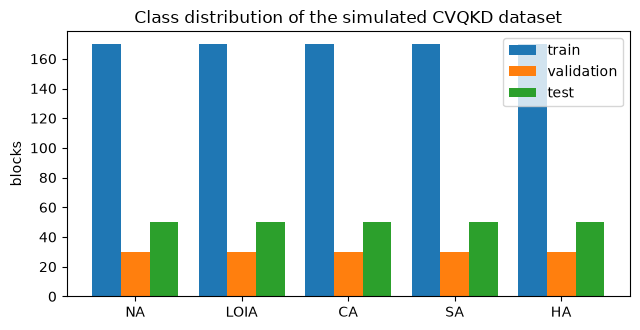

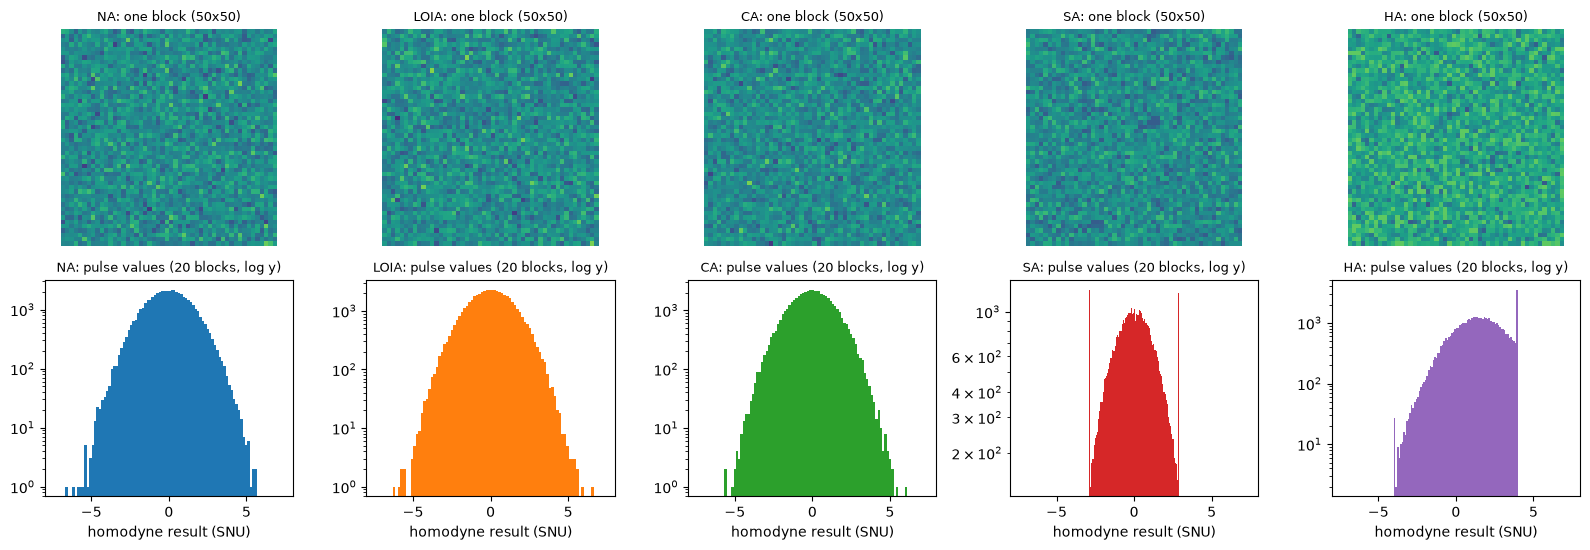

In [7]:
# class distribution (real class counts of the simulated dataset, per split)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
xs = np.arange(len(CLASSES)); w_ = 0.27
for j, (nm, yy) in enumerate([("train", ytr), ("validation", yva), ("test", yte)]):
    ax.bar(xs + (j - 1) * w_, np.bincount(yy.numpy(), minlength=5), w_, label=nm)
ax.set_xticks(xs); ax.set_xticklabels(CLASSES); ax.set_ylabel("blocks"); ax.set_title("Class distribution of the simulated CVQKD dataset"); ax.legend()
plt.tight_layout(); plt.show()

# one example block per class (as the CNN sees it) and the pulse-value histograms
pal = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for k, c in enumerate(CLASSES):
    i = np.where(y_ALL[idx_tr] == k)[0][0]
    axes[0, k].imshow(Xtr[i, 0].numpy(), cmap="viridis", vmin=0, vmax=1); axes[0, k].set_title(f"{c}: one block ({SIDE}x{SIDE})", fontsize=9); axes[0, k].axis("off")
    axes[1, k].hist(X_ALL[y_ALL == k][:20].ravel(), bins=80, color=pal(k), log=True); axes[1, k].set_title(f"{c}: pulse values (20 blocks, log y)", fontsize=9)
    axes[1, k].set_xlim(-8, 8); axes[1, k].set_xlabel("homodyne result (SNU)")
plt.tight_layout(); plt.show()

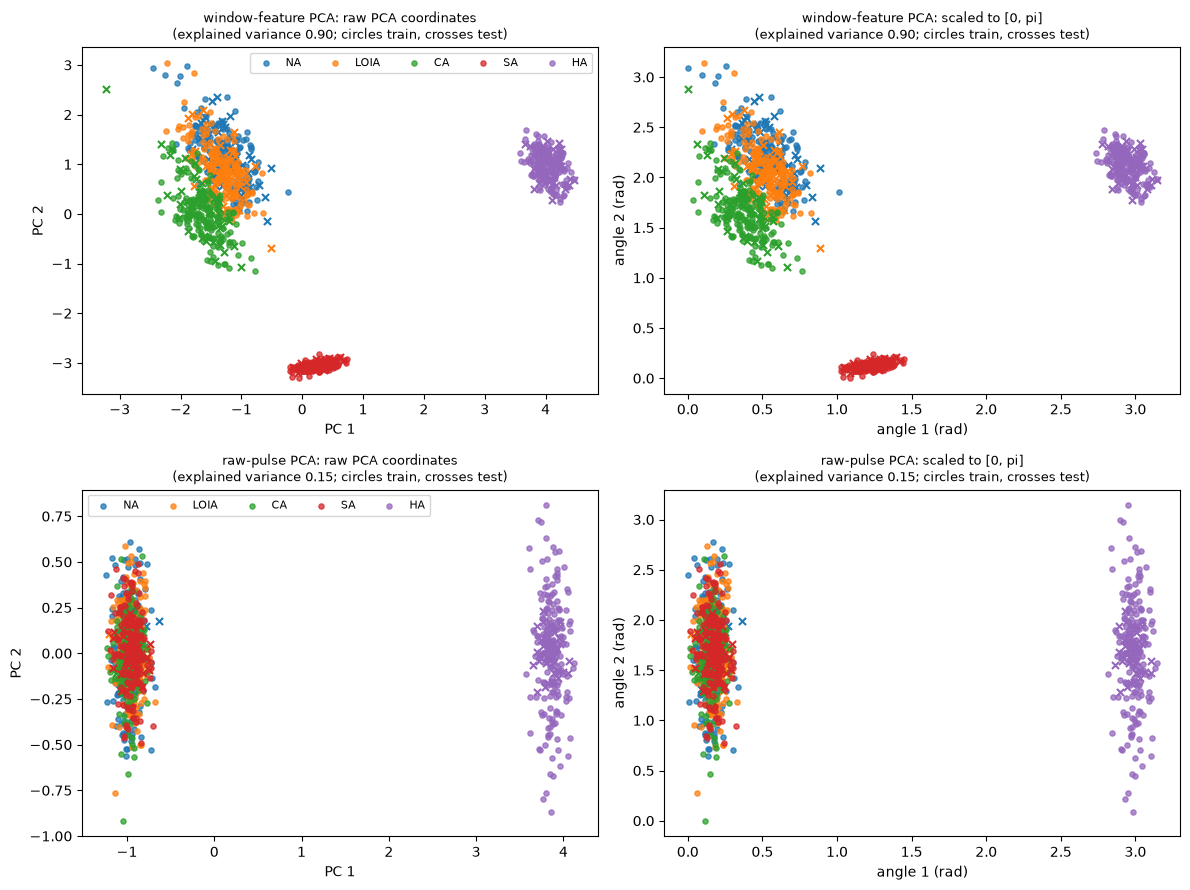

In [8]:
# 2-D scatter plots of the real blocks coloured by the ground-truth class (PCA fitted on the training split only)
F_tr, F_te = window_features(X_ALL[idx_tr]), window_features(X_ALL[idx_te])
sc_f = StandardScaler().fit(F_tr)
pca_f = PCA(2, random_state=SEED).fit(sc_f.transform(F_tr))
Pf_tr, Pf_te = pca_f.transform(sc_f.transform(F_tr)), pca_f.transform(sc_f.transform(F_te))
pca_r = PCA(2, svd_solver="randomized", random_state=SEED).fit(Xtr.reshape(len(Xtr), -1).numpy())
Pr_tr, Pr_te = pca_r.transform(Xtr.reshape(len(Xtr), -1).numpy()), pca_r.transform(Xte.reshape(len(Xte), -1).numpy())

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for r_, (name, A_tr, A_te, pca) in enumerate([("window-feature PCA", Pf_tr, Pf_te, pca_f), ("raw-pulse PCA", Pr_tr, Pr_te, pca_r)]):
    mm = MinMaxScaler((0, np.pi)).fit(A_tr)                                   # [0, pi] angles, fitted on the training split only
    for c_, (B_tr, B_te, ttl) in enumerate([(A_tr, A_te, "raw PCA coordinates"), (mm.transform(A_tr), np.clip(mm.transform(A_te), 0, np.pi), "scaled to [0, pi]")]):
        ax = axes[r_, c_]
        for k, c in enumerate(CLASSES):
            ax.scatter(B_tr[ytr.numpy() == k, 0], B_tr[ytr.numpy() == k, 1], s=14, color=pal(k), label=c, alpha=.75)
            ax.scatter(B_te[yte.numpy() == k, 0], B_te[yte.numpy() == k, 1], s=26, color=pal(k), marker="x")
        ax.set_title(f"{name}: {ttl}\n(explained variance {pca.explained_variance_ratio_.sum():.2f}; circles train, crosses test)", fontsize=9)
        ax.set_xlabel("PC 1" if c_ == 0 else "angle 1 (rad)"); ax.set_ylabel("PC 2" if c_ == 0 else "angle 2 (rad)")
    axes[r_, 0].legend(fontsize=8, ncol=5)
plt.tight_layout(); plt.show()

Reading the pictures. In the window-feature PCA the saturation, hybrid and calibration blocks form their own clouds (a
clipped distribution has a hard maximum; the hybrid attack shifts the mean and broadens the distribution; the calibration
attack shrinks the standard deviation by about 7 %), whereas **NA and LOIA overlap strongly**: the LOIA changes the standard
deviation by only a few percent (table above), which is comparable to the sampling noise of a block's standard deviation. This is
the same difficulty that the paper reports. The raw-pulse PCA shows almost nothing: the pulses of a block are independent noise,
so the useful information is in *statistics* of the block, which a CNN must learn to compute.

## 3. Classical reference points on the same blocks

Before any neural network, two reference points on the *same* simulated blocks:

* **Hand-made window features** (the eight statistics above) fed to a random forest and to an RBF-kernel SVM, both trained on the
  training split only. They tell us how hard the task is for a classical model that is allowed to compute any statistic.
* **A variance threshold for the NA-versus-LOIA pair**: the single best threshold on the block variance, chosen on the
  training blocks. It estimates the *ceiling* for the hardest pair of the dataset. Perfect separation of CA, SA and HA plus this
  pair accuracy gives the best overall accuracy that a variance-only detector could reach.

In [9]:
Ftr_full = window_features(X_ALL[idx_tr_full]); Fte = window_features(X_ALL[idx_te])
rf = RandomForestClassifier(300, random_state=SEED).fit(Ftr_full, y_ALL[idx_tr_full])
sc_ = StandardScaler().fit(Ftr_full)
svc = SVC(C=10, gamma="scale", random_state=SEED).fit(sc_.transform(Ftr_full), y_ALL[idx_tr_full])
REF = {"RandomForest on 8 window features": rf.predict(Fte), "SVC (rbf) on 8 window features": svc.predict(sc_.transform(Fte))}

# NA-versus-LOIA ceiling: best variance threshold on the training blocks, accuracy on the test blocks
v_all = X_ALL.var(1)
mtr = np.isin(y_ALL[idx_tr_full], [0, 1]); mte = np.isin(y_ALL[idx_te], [0, 1])
vtr, ltr = v_all[idx_tr_full][mtr], y_ALL[idx_tr_full][mtr]
cand = np.sort(vtr); thr = max(cand, key=lambda t_: ((vtr > t_) == (ltr == 0)).mean())      # NA has the larger variance
pair_acc = ((v_all[idx_te][mte] > thr) == (y_ALL[idx_te][mte] == 0)).mean()
CEILING = (3 + 2 * pair_acc) / 5
print(f"variance-threshold accuracy on the NA/LOIA pair (test): {pair_acc:.3f}  ->  best overall accuracy of a variance-only detector about {CEILING:.3f}")
rows = [{"model": k, "test accuracy": accuracy_score(y_ALL[idx_te], p)} for k, p in REF.items()]
display(pd.DataFrame(rows).round(4))
print("confusion matrix of the random forest (rows: true NA, LOIA, CA, SA, HA):"); print(confusion_matrix(y_ALL[idx_te], REF["RandomForest on 8 window features"]))

variance-threshold accuracy on the NA/LOIA pair (test): 0.650  ->  best overall accuracy of a variance-only detector about 0.860


,model,test accuracy
0,RandomForest on 8 window features,0.848
1,SVC (rbf) on 8 window features,0.840


confusion matrix of the random forest (rows: true NA, LOIA, CA, SA, HA):
[[37 13  0  0  0]
 [20 28  2  0  0]
 [ 0  3 47  0  0]
 [ 0  0  0 50  0]
 [ 0  0  0  0 50]]


## Quantum Circuit Architecture

The VQC of the paper (Sec. 3.3 and 4.4): for every one of the **L = 4** layers the n classical features (already scaled to
[-pi, pi]) are written onto the qubits with an **RY rotation** (angle encoding, repeated in every layer = data re-uploading),
followed by one layer of **StronglyEntanglingLayers**: a general rotation `Rot(phi, theta, omega)` on each qubit and a ring of
CNOT gates; finally the **Pauli-Z expectation value of every qubit** is measured. For n = 8 qubits there are
4 x 8 x 3 = 96 trainable parameters, as in Sec. 5.5.

*Assumptions where the paper is silent.* (i) The CNOT range of layer l is (l mod (n - 1)) + 1, which is what a single 4-layer
`StronglyEntanglingLayers` uses (the paper only says "CNOT gates between neighbouring qubits"); (ii) weights start uniform in
[0, 2 pi); (iii) the qubit-scaling study uses n = 4, 6, 8, 10 with the same recipe, so each n is a distinct architecture and
is drawn below. The drawings are made from the PennyLane QNode with `level="device"`, i.e. after decomposition into the gates
that the simulator really executes (`RY`, `Rot`, `CNOT`).

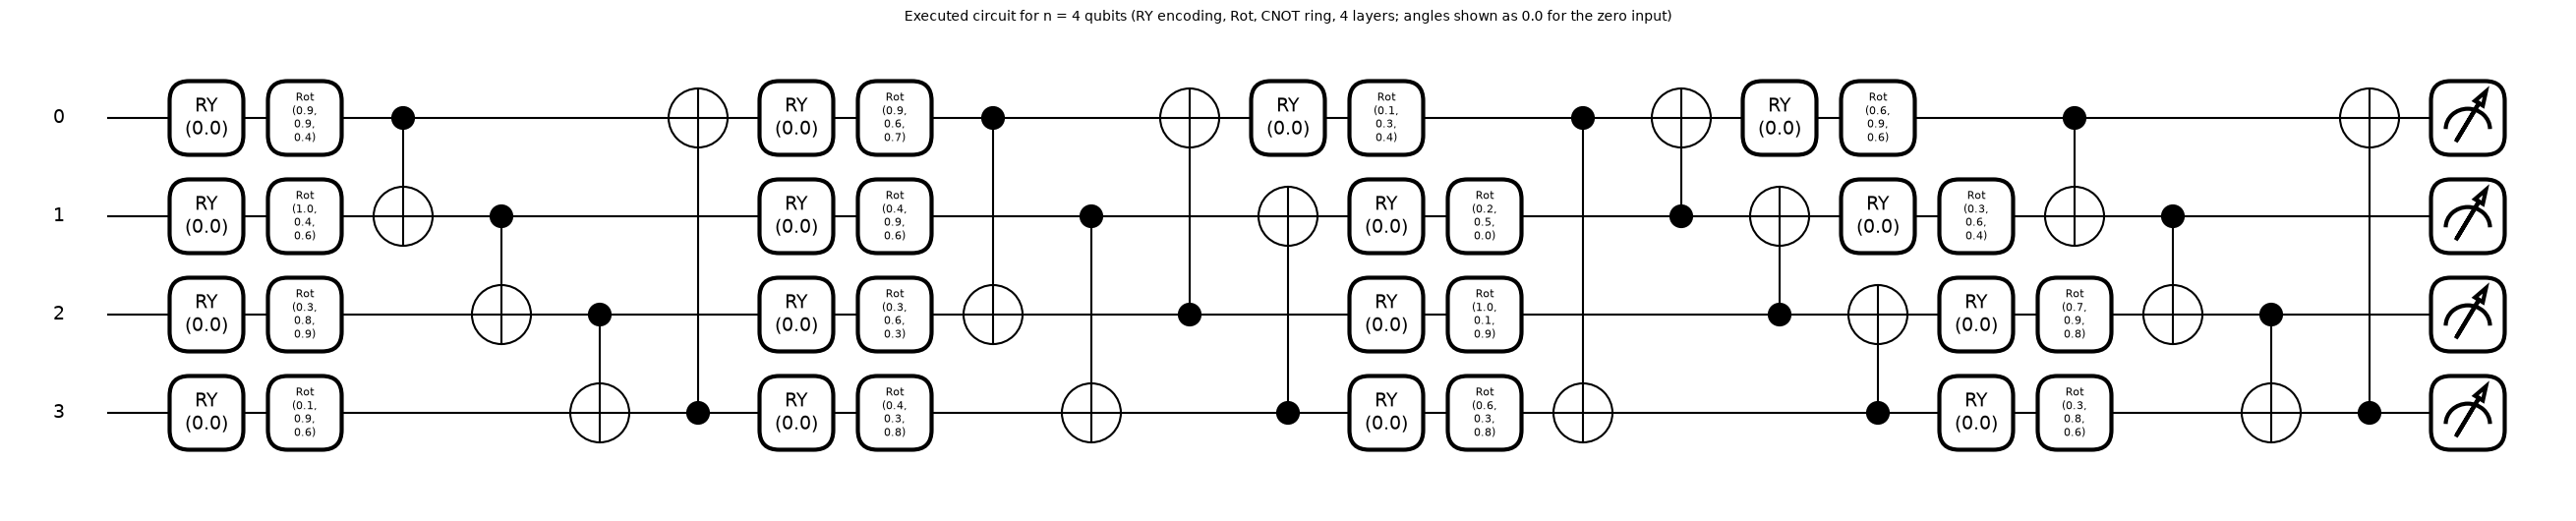

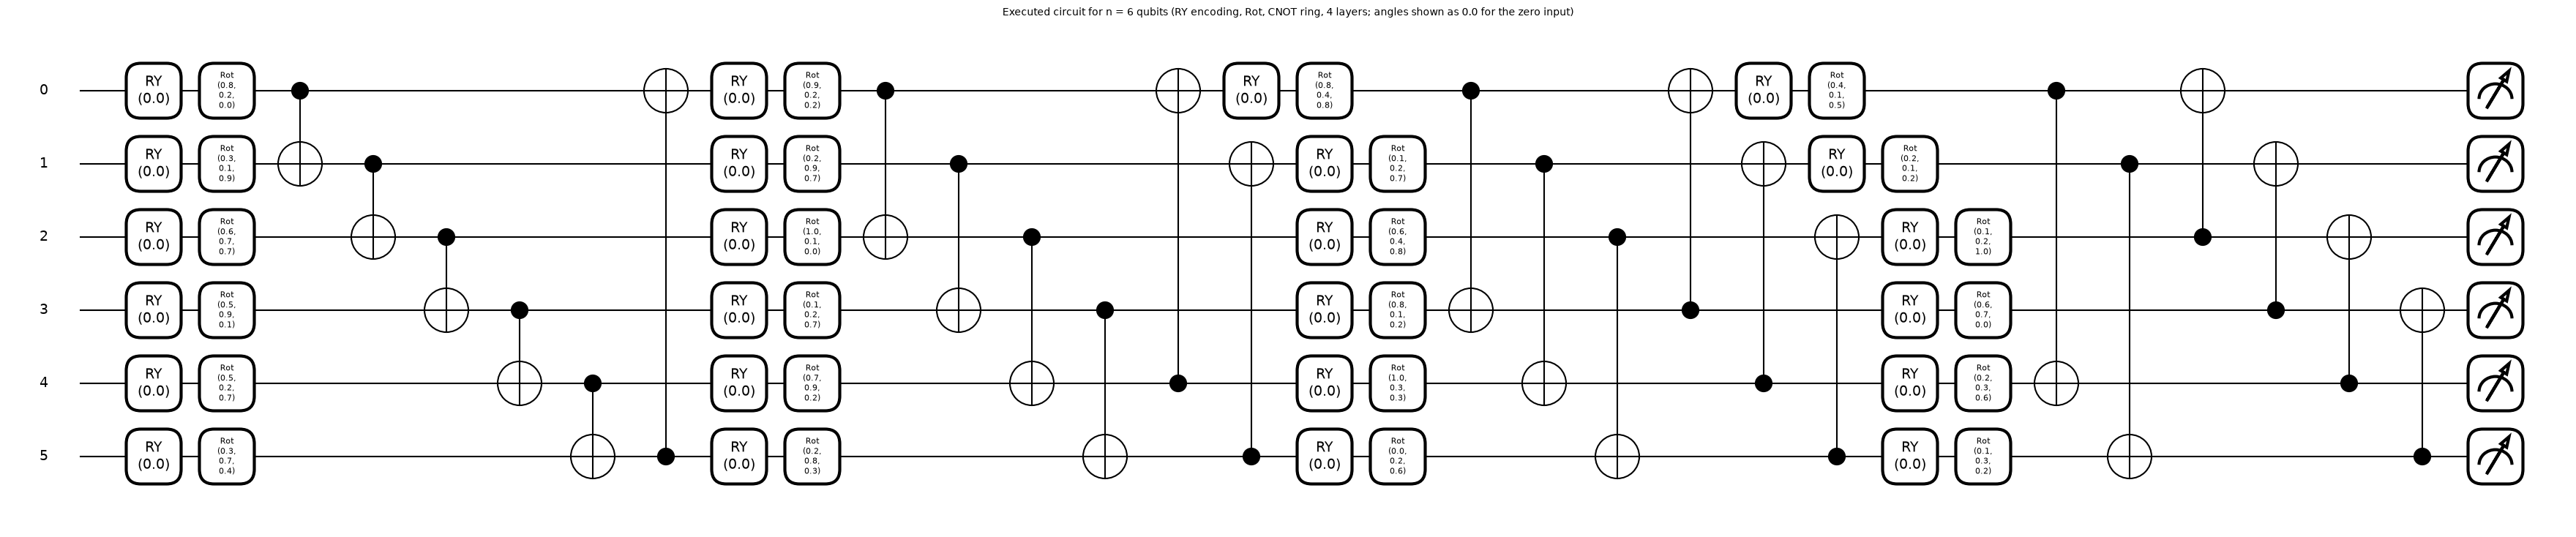

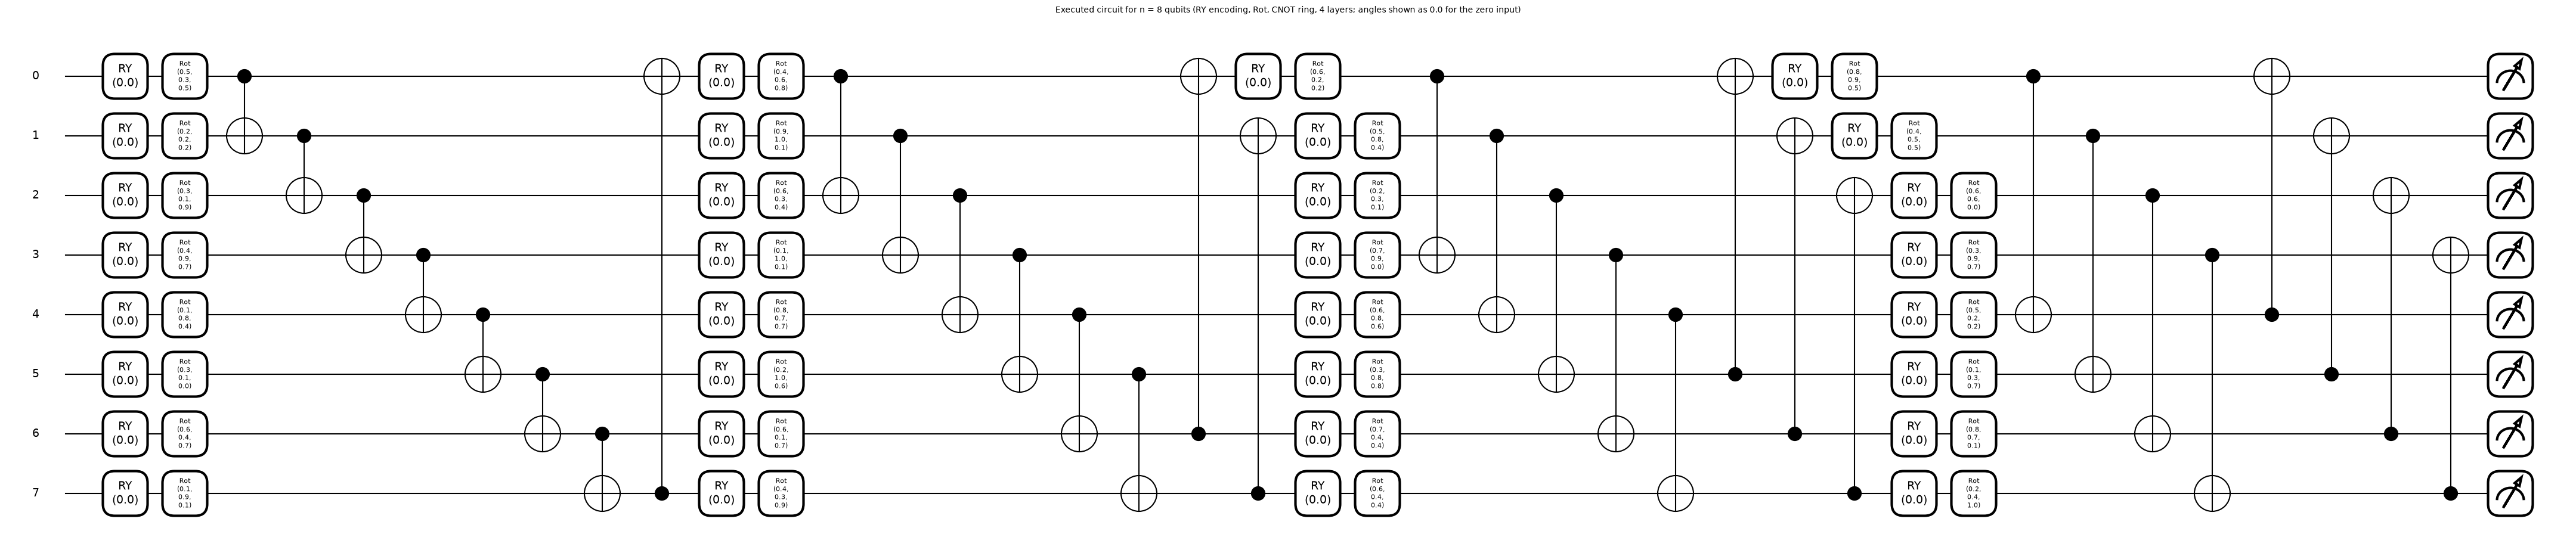

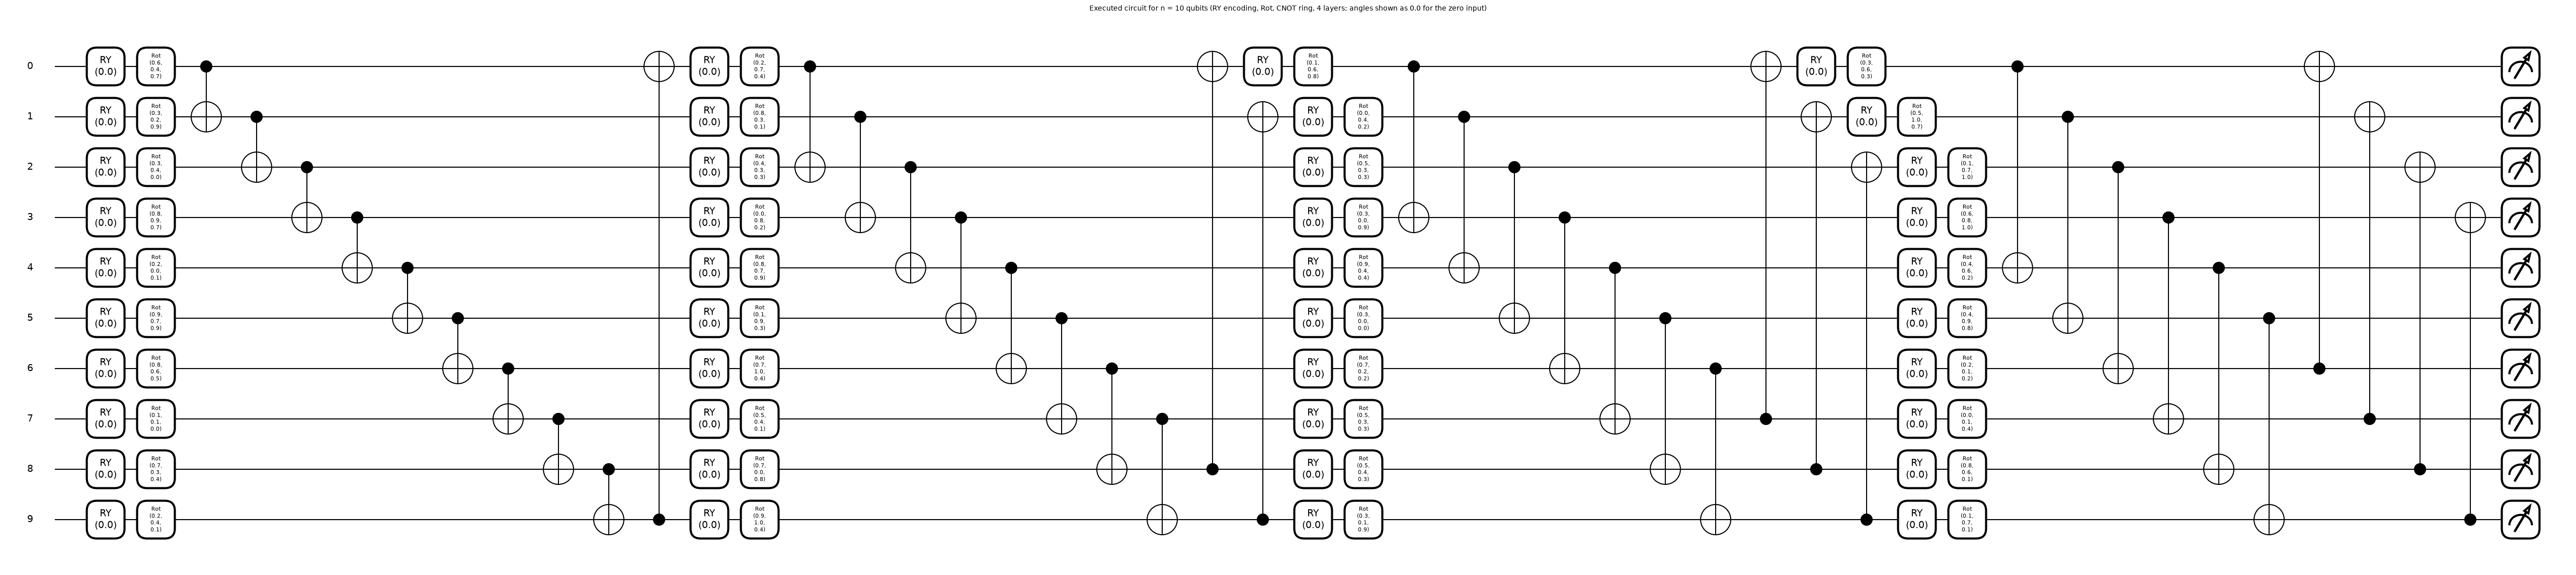

,qubits,depth,gates,gate types,trainable parameters,measurements
0,4,21,48,"{'RY': 16, 'Rot': 16, 'CNOT': 16}",48,<Z> on 4 qubits
1,6,22,72,"{'RY': 24, 'Rot': 24, 'CNOT': 24}",72,<Z> on 6 qubits
2,8,25,96,"{'RY': 32, 'Rot': 32, 'CNOT': 32}",96,<Z> on 8 qubits
3,10,29,120,"{'RY': 40, 'Rot': 40, 'CNOT': 40}",120,<Z> on 10 qubits


In [10]:
def sel_ranges(n, L): return [(l % (n - 1)) + 1 for l in range(L)]

def make_qnode(n, L=VQC_LAYERS):
    """The paper's VQC as a PennyLane QNode: [AngleEmbedding(RY) + StronglyEntanglingLayers layer] x L, <Z_i> on every qubit."""
    dev = qml.device("default.qubit", wires=n)
    rg = sel_ranges(n, L)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for l in range(L):
            qml.AngleEmbedding(inputs, wires=range(n), rotation="Y")                      # data (re-)uploading
            qml.StronglyEntanglingLayers(weights[l:l + 1], wires=range(n), ranges=[rg[l]])  # Rot on every qubit + CNOT ring
        return [qml.expval(qml.PauliZ(q)) for q in range(n)]
    return circuit

rows = []
for n in sorted(set(QUBIT_LIST) | {N_QUBITS}):
    qn = make_qnode(n)
    xs_, ws_ = torch.zeros(n), torch.rand(VQC_LAYERS, n, 3)
    res = qml.specs(qn, level="device")(xs_, ws_)["resources"]
    fig, ax = qml.draw_mpl(qn, decimals=1, level="device")(xs_, ws_)
    fig.suptitle(f"Executed circuit for n = {n} qubits (RY encoding, Rot, CNOT ring, 4 layers; angles shown as 0.0 for the zero input)", fontsize=10, y=1.02)
    plt.show()
    rows.append({"qubits": n, "depth": res.depth, "gates": res.num_gates, "gate types": dict(res.gate_types), "trainable parameters": ws_.numel(), "measurements": f"<Z> on {n} qubits"})
display(pd.DataFrame(rows))

**Training simulator and equivalence check.** Training goes through the circuit thousands of times with back-propagation, and
PennyLane's `default.qubit` is slow for that on a CPU. The notebook therefore also contains a small batched PyTorch
state-vector simulator, `FastVQC`, that applies the **same gate list** (RY encoding, `Rot`, CNOT ring, Pauli-Z read-out). The cell
below asserts that its outputs and its weight gradients equal those of the QNode drawn above for every n.

In [11]:
def kron_list(mats):
    M = mats[0]
    for m in mats[1:]:
        a, b = M.shape[-1], m.shape[-1]
        M = torch.einsum("...ij,...kl->...ikjl", M, m).reshape(*M.shape[:-2], a * b, a * b)
    return M

class FastVQC(nn.Module):
    """Batched state-vector simulation of exactly the gates of make_qnode (qubit 0 = most significant bit)."""
    def __init__(self, n, L=VQC_LAYERS):
        super().__init__(); self.n, self.L, self.h = n, L, n // 2
        self.weights = nn.Parameter(torch.rand(L, n, 3) * 2 * np.pi)              # CHOICE: uniform [0, 2 pi) initial angles
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
        self.register_buffer("zsign", torch.tensor(1 - 2 * bits, dtype=torch.float32))      # eigenvalue of Z_q on each basis state
        self.inv = []
        for l in range(L):                                                         # CNOT(i -> (i + r) mod n) for i = 0..n-1 as a permutation of basis states
            r = sel_ranges(n, L)[l]; p = idx.copy()
            for i in range(n):
                t_ = (i + r) % n; b = (p >> (n - 1 - i)) & 1
                p = np.where(b == 1, p ^ (1 << (n - 1 - t_)), p)
            self.inv.append(torch.tensor(np.argsort(p)))                           # new_state[j] = state[inv[j]]
    def forward(self, x):
        B, n = x.shape; h = self.h
        c, s = torch.cos(x / 2), torch.sin(x / 2)                                  # RY(x_q) on every qubit; identical in every layer (re-uploading), so built once
        ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex64)      # (B, n, 2, 2)
        Ea, EbT = kron_list([ry[:, q] for q in range(h)]), kron_list([ry[:, q] for q in range(h, n)]).transpose(1, 2)   # the n-qubit RY layer = Ea (x) Eb
        w = self.weights; phi, th, om = w[..., 0], w[..., 1], w[..., 2]            # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi), all layers at once
        ct, stt = torch.cos(th / 2), torch.sin(th / 2); e = lambda a: torch.exp(1j * a)
        rot = torch.stack([torch.stack([e(-(phi + om) / 2) * ct, -e((phi - om) / 2) * stt], -1),
                           torch.stack([e(-(phi - om) / 2) * stt, e((phi + om) / 2) * ct], -1)], -2).to(torch.complex64)   # (L, n, 2, 2)
        st = torch.zeros(B, 2 ** n, dtype=torch.complex64, device=x.device); st[:, 0] = 1
        for l in range(self.L):
            st = torch.matmul(torch.matmul(Ea, st.reshape(B, 2 ** h, -1)), EbT)                                   # data (re-)uploading
            Ra, RbT = kron_list([rot[l, q] for q in range(h)]), kron_list([rot[l, q] for q in range(h, n)]).T     # trainable rotations
            st = torch.matmul(torch.matmul(Ra, st), RbT).reshape(B, -1)
            st = st[:, self.inv[l]]                                                                                # the CNOT ring
        return (st.real ** 2 + st.imag ** 2) @ self.zsign                           # <Z_q> for every qubit

for n in sorted(set(QUBIT_LIST) | {N_QUBITS}):
    qn, fv = make_qnode(n), FastVQC(n)
    xx = (torch.rand(6, n) * 2 - 1) * np.pi
    ww = fv.weights.detach().clone().requires_grad_(True)
    ref = torch.stack(qn(xx, ww), 1); ref.pow(2).sum().backward(); g_ref = ww.grad.clone()
    out = fv(xx); out.pow(2).sum().backward(); g_fast = fv.weights.grad
    d_out, d_grad = (ref - out).abs().max().item(), (g_ref - g_fast).abs().max().item()
    assert d_out < 1e-5 and d_grad < 1e-4, (n, d_out, d_grad)
    print(f"n = {n:2d} qubits: max |output difference| = {d_out:.1e}, max |gradient difference| = {d_grad:.1e}  -> FastVQC == QNode of the drawing")

n =  4 qubits: max |output difference| = 3.1e-07, max |gradient difference| = 5.1e-07  -> FastVQC == QNode of the drawing
n =  6 qubits: max |output difference| = 1.6e-07, max |gradient difference| = 2.2e-07  -> FastVQC == QNode of the drawing


n =  8 qubits: max |output difference| = 1.3e-07, max |gradient difference| = 1.3e-07  -> FastVQC == QNode of the drawing


n = 10 qubits: max |output difference| = 2.5e-07, max |gradient difference| = 6.2e-08  -> FastVQC == QNode of the drawing


## 4. The models

* **HQCNN (the paper's model).** CNN feature extractor -> Linear(. -> d = 32) -> *transition* Linear(32 -> n) + Tanh, times pi ->
  VQC (n qubits, 4 re-uploading layers) -> Linear(n -> 5) -> softmax.
* **ResNet (the paper's baseline).** Four residual blocks with 32, 64, 128, 256 channels (the same depth and widths as the CNN),
  global average pooling and a fully connected layer.
* **CNN + classical head (our ablation).** The identical CNN and transition, but the VQC is replaced by one classical layer
  `Linear(n, n) + Tanh` (72 parameters, about the size of the VQC's 96). It answers the question the paper does not ask:
  *does the quantum circuit matter, or is the CNN doing all the work?*

In [12]:
class Extractor(nn.Module):
    def __init__(self, d=32):
        super().__init__(); L = []; c = 1
        for o in (32, 64, 128, 256):                                   # four 3x3 convolutions with 32/64/128/256 channels (paper); stride 2 reduces the resolution
            L += [nn.Conv2d(c, o, 3, stride=2, padding=1), nn.BatchNorm2d(o), nn.ReLU()]; c = o        # CHOICE: BatchNorm
        self.conv = nn.Sequential(*L); self.fc = nn.Linear(512, d)     # CHOICE: mean + max pooling -> 512 -> d = 32 features (Sec. 5.5)
    def forward(self, x):
        h = self.conv(x); h = torch.cat([h.mean((2, 3)), h.amax((2, 3))], 1)
        return F.relu(self.fc(h))

class HQCNN(nn.Module):
    def __init__(self, n, quantum=True, L=VQC_LAYERS, d=32, ncls=5):
        super().__init__(); self.n = n; self.quantum = quantum
        self.extractor = Extractor(d); self.to_q = nn.Linear(d, n)                        # transition layer: compress to n values
        self.core = FastVQC(n, L) if quantum else nn.Sequential(nn.Linear(n, n), nn.Tanh())
        self.head = nn.Linear(n, ncls)                                                    # post-quantum layer -> 5 logits
    def angles(self, x): return np.pi * torch.tanh(self.to_q(self.extractor(x)))        # Tanh -> [-1, 1], scaled to [-pi, pi]
    def forward(self, x): return self.head(self.core(self.angles(x)))

class Block(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False); self.b2 = nn.BatchNorm2d(cout)
        self.sc = nn.Sequential(nn.Conv2d(cin, cout, 1, stride=2, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        o = F.relu(self.b1(self.c1(x))); o = self.b2(self.c2(o)); return F.relu(o + self.sc(x))

class ResNetSmall(nn.Module):
    def __init__(self, ncls=5):
        super().__init__(); L = []; c = 1
        for o in (32, 64, 128, 256): L.append(Block(c, o)); c = o
        self.body = nn.Sequential(*L, nn.AdaptiveAvgPool2d(1), nn.Flatten()); self.fc = nn.Linear(256, ncls)
    def forward(self, x): return self.fc(self.body(x))

def nparams(m, prefix=None): return sum(p.numel() for k, p in m.named_parameters() if prefix is None or k.startswith(prefix))

def recal_bn(model, X, n=256):
    """Re-estimate the BatchNorm statistics on n training blocks (cumulative average) before every evaluation: the class signal is a
    few percent of the activation scale, so the usual running average over the last few batches is too noisy for evaluation."""
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
    if not bns: return
    for m in bns: m.reset_running_stats(); m.momentum = None
    model.train()
    with torch.no_grad():
        for i in range(0, min(n, len(X)), 64): model(X[i:i + 64])
    for m in bns: m.momentum = 0.1

def predict(model, X, bs=250):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(model(X[i:i + bs]).argmax(1))
    return torch.cat(out).numpy()

def train_model(model, data, epochs, seed, lr_cls=LR_CLASSICAL, lr_q=LR_QUANTUM, bs=BATCH, tag="", verbose=True):
    """Adam with two parameter groups (classical / quantum weights), cross-entropy. The epoch with the best VALIDATION accuracy is restored."""
    Xtr_, ytr_, Xva_, yva_, Xte_, yte_ = data
    torch.manual_seed(seed); r = np.random.default_rng(seed)
    qp = [p for k, p in model.named_parameters() if k.startswith("core.weights")]
    cp = [p for k, p in model.named_parameters() if not k.startswith("core.weights")]
    opt = torch.optim.Adam([{"params": cp, "lr": lr_cls}] + ([{"params": qp, "lr": lr_q}] if qp else []))
    sched =torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=0.0)      # CHOICE: cosine decay (short budget)
    H = {k: [] for k in ["loss", "train_acc", "val_acc", "test_acc"]}; best_val, best_state, best_ep = -1, None, 0; t0 = time.time()
    for ep in range(epochs):
        model.train(); order = r.permutation(len(Xtr_)); tot = cor = 0
        for i in range(0, len(order), bs):
            idx = order[i:i + bs]; xb, yb = Xtr_[idx], ytr_[idx]
            fl = xb.flatten(1); xb = torch.gather(fl, 1, torch.rand_like(fl).argsort(1)).reshape(xb.shape)    # CHOICE: random pulse order (train only)
            lg = model(xb); loss = F.cross_entropy(lg, yb); opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx); cor += (lg.argmax(1) == yb).sum().item()
        sched.step()
        recal_bn(model, Xtr_[torch.from_numpy(r.permutation(len(Xtr_))[:256])])            # training blocks only
        pv, pt = predict(model, Xva_), predict(model, Xte_)
        H["loss"].append(tot / len(order)); H["train_acc"].append(cor / len(order))
        H["val_acc"].append(float((pv == yva_.numpy()).mean())); H["test_acc"].append(float((pt == yte_.numpy()).mean()))
        if H["val_acc"][-1] > best_val: best_val, best_ep, best_state = H["val_acc"][-1], ep, {k: v.clone() for k, v in model.state_dict().items()}
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(f"  {tag} epoch {ep + 1:3d}/{epochs}: loss {H['loss'][-1]:.3f} | train acc {H['train_acc'][-1]:.3f} | val acc {H['val_acc'][-1]:.3f} | test acc {H['test_acc'][-1]:.3f} | {time.time() - t0:.0f} s", flush=True)
    model.load_state_dict(best_state)
    return H, best_ep, time.time() - t0

torch.manual_seed(SEED)
m_h, m_c, m_r = HQCNN(N_QUBITS), HQCNN(N_QUBITS, quantum=False), ResNetSmall()
print(f"HQCNN: {nparams(m_h):,} parameters in total ({nparams(m_h, 'core'):,} in the VQC)  |  CNN + classical head: {nparams(m_c):,} ({nparams(m_c, 'core'):,} in the head layer)  |  ResNet: {nparams(m_r):,}")

HQCNN: 405,621 parameters in total (96 in the VQC)  |  CNN + classical head: 405,597 (72 in the head layer)  |  ResNet: 1,217,925


## 5. Training and Table 1 / Fig. 4

Each model is trained for the epochs set in the configuration cell, with Adam (two learning rates for the HQCNN as in the paper). After
training, the weights of the epoch with the **best validation accuracy** are used for the test set. The tables below report the
test-set metrics of that model (the honest number), the accuracy after the last epoch, and, for comparison with the paper's
protocol, the best test accuracy over all epochs ("Best Model Saving" on the test set), which is optimistic.

In [13]:
RUNS = {}          # (model name, seed) -> dict(H, best_ep, time, pred, model state)
def run(name, factory, seed, epochs=EPOCHS):
    torch.manual_seed(seed); m = factory()
    H, be, tm = train_model(m, DATA, epochs, seed, tag=f"{name} s{seed}")
    RUNS[(name, seed)] = dict(H=H, best_ep=be, time=tm, pred=predict(m, Xte), model=m)
    print(f"-> {name} seed {seed}: test accuracy (best-validation epoch {be + 1}) = {accuracy_score(yte.numpy(), RUNS[(name, seed)]['pred']):.4f}  ({tm:.0f} s)")

for s in MODEL_SEEDS:
    run("HQCNN", lambda: HQCNN(N_QUBITS), s)
    run("ResNet", lambda: ResNetSmall(), s)
    run("CNN + classical head", lambda: HQCNN(N_QUBITS, quantum=False), s)

  HQCNN s42 epoch   1/30: loss 1.592 | train acc 0.200 | val acc 0.200 | test acc 0.200 | 7 s


  HQCNN s42 epoch   4/30: loss 1.227 | train acc 0.396 | val acc 0.400 | test acc 0.400 | 26 s


  HQCNN s42 epoch   7/30: loss 1.153 | train acc 0.386 | val acc 0.400 | test acc 0.400 | 45 s


  HQCNN s42 epoch  10/30: loss 1.124 | train acc 0.396 | val acc 0.440 | test acc 0.424 | 65 s


  HQCNN s42 epoch  13/30: loss 1.102 | train acc 0.473 | val acc 0.620 | test acc 0.624 | 82 s


...

  CNN + classical head s42 epoch  22/30: loss 0.910 | train acc 0.604 | val acc 0.687 | test acc 0.660 | 125 s


  CNN + classical head s42 epoch  25/30: loss 0.868 | train acc 0.647 | val acc 0.693 | test acc 0.672 | 140 s


  CNN + classical head s42 epoch  28/30: loss 0.837 | train acc 0.651 | val acc 0.660 | test acc 0.676 | 155 s


  CNN + classical head s42 epoch  30/30: loss 0.844 | train acc 0.656 | val acc 0.687 | test acc 0.668 | 166 s


-> CNN + classical head seed 42: test accuracy (best-validation epoch 21) = 0.6800  (166 s)


,class,model,recall,F1,accuracy (one-vs-rest)
0,NA,HQCNN,0.92,0.63,0.78
1,NA,ResNet,0.70,0.71,0.89
2,NA,CNN + classical head,0.78,0.63,0.82
3,LOIA,HQCNN,0.02,0.04,0.78
4,LOIA,ResNet,0.54,0.58,0.84
5,LOIA,CNN + classical head,0.18,0.25,0.79
6,CA,HQCNN,0.90,0.74,0.87
7,CA,ResNet,0.94,0.90,0.96
8,CA,CNN + classical head,0.92,0.82,0.92
9,SA,HQCNN,0.26,0.34,0.80


,HQCNN,ResNet,CNN + classical head
overall accuracy (best-validation epoch),0.6200,0.8200,0.6800
accuracy after the last epoch,0.6360,0.8160,0.6680
"best test accuracy over epochs (paper-style, optimistic)",0.6560,0.8280,0.6840
training time (s),238.8503,494.4871,165.9716


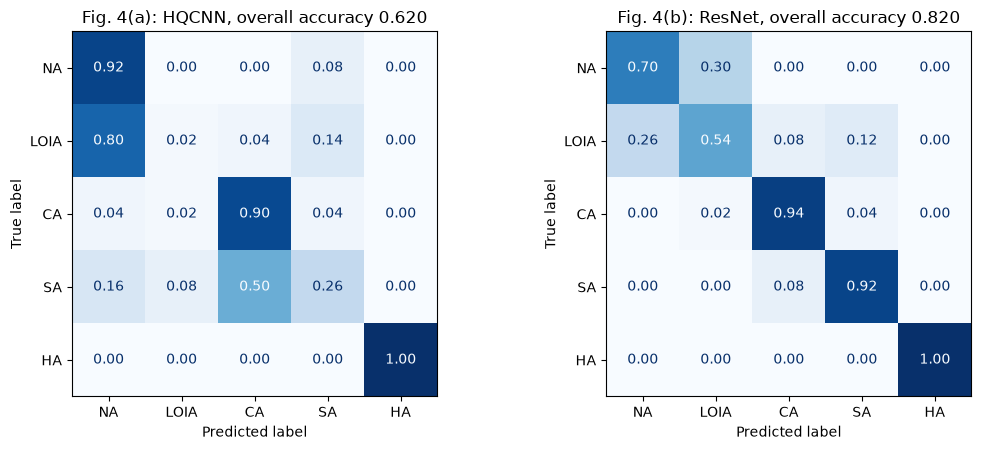

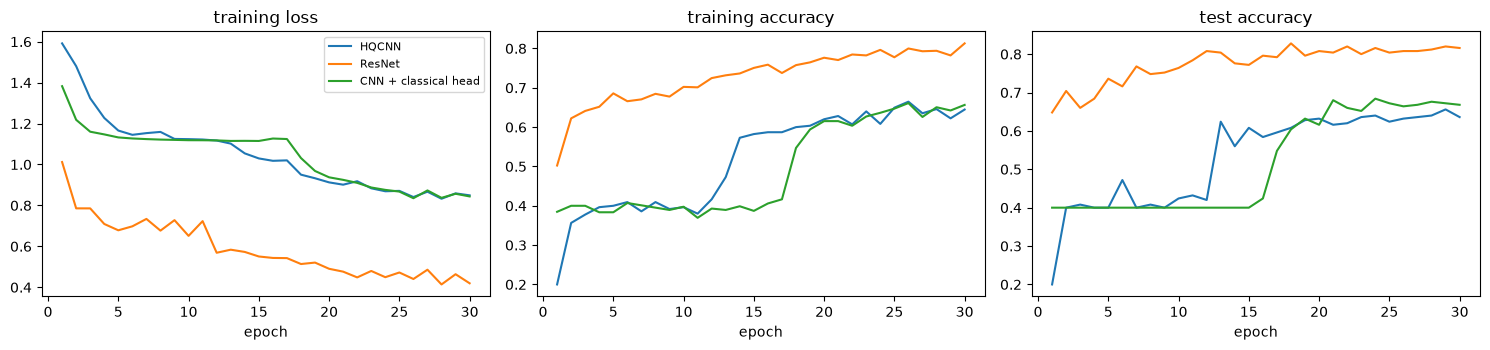

In [14]:
def summarize(name, seed):
    r_ = RUNS[(name, seed)]; yt = yte.numpy(); p = r_["pred"]
    cm = confusion_matrix(yt, p, labels=range(5))
    pr, rc, f1, _ = precision_recall_fscore_support(yt, p, labels=range(5), zero_division=0)
    acc_c = [(cm.sum() - cm[k].sum() - cm[:, k].sum() + 2 * cm[k, k]) / cm.sum() for k in range(5)]     # one-vs-rest accuracy of class k
    return dict(cm=cm, precision=pr, recall=rc, f1=f1, acc_class=acc_c, overall=accuracy_score(yt, p))

# ---- Table 1 (seed = first model seed): per-class recall, F1, accuracy, overall accuracy
s0 = MODEL_SEEDS[0]
rows = []
for k, c in enumerate(CLASSES):
    for name in ["HQCNN", "ResNet", "CNN + classical head"]:
        sm = summarize(name, s0)
        rows.append({"class": c, "model": name, "recall": sm["recall"][k], "F1": sm["f1"][k], "accuracy (one-vs-rest)": sm["acc_class"][k]})
T1 = pd.DataFrame(rows)
display(T1.round(2))
overall = pd.DataFrame({name: {"overall accuracy (best-validation epoch)": summarize(name, s0)["overall"],
                               "accuracy after the last epoch": RUNS[(name, s0)]["H"]["test_acc"][-1],
                               "best test accuracy over epochs (paper-style, optimistic)": max(RUNS[(name, s0)]["H"]["test_acc"]),
                               "training time (s)": RUNS[(name, s0)]["time"]} for name in ["HQCNN", "ResNet", "CNN + classical head"]})
display(overall.round(4))
if len(MODEL_SEEDS) > 1:
    ms = pd.DataFrame({name: {"mean": np.mean([summarize(name, s)["overall"] for s in MODEL_SEEDS]), "std": np.std([summarize(name, s)["overall"] for s in MODEL_SEEDS]),
                              **{f"seed {s}": summarize(name, s)["overall"] for s in MODEL_SEEDS}} for name in ["HQCNN", "ResNet", "CNN + classical head"]})
    print("overall test accuracy over model seeds:"); display(ms.round(4))

# ---- Fig. 4: normalised confusion matrices of the HQCNN and the ResNet
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, name, lab in zip(axes, ["HQCNN", "ResNet"], "ab"):
    cm = summarize(name, s0)["cm"]
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues", values_format=".2f")
    ax.set_title(f"Fig. 4({lab}): {name}, overall accuracy {summarize(name, s0)['overall']:.3f}")
plt.tight_layout(); plt.show()

# ---- learning curves
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for name in ["HQCNN", "ResNet", "CNN + classical head"]:
    H = RUNS[(name, s0)]["H"]; ep = np.arange(1, len(H["loss"]) + 1)
    axes[0].plot(ep, H["loss"], label=name); axes[1].plot(ep, H["train_acc"], label=name); axes[2].plot(ep, H["test_acc"], label=name)
for ax, t_ in zip(axes, ["training loss", "training accuracy", "test accuracy"]): ax.set_xlabel("epoch"); ax.set_title(t_)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**What the HQCNN's quantum layer sees.** The 8 angles that leave the transition layer are the only information the VQC receives. The
scatter below shows the test blocks in the plane of the first two angles (rescaled from [-pi, pi] to [0, pi]), coloured by the
ground-truth class, next to a PCA of all 8 angles: it shows which attacks the CNN already separated *before* the quantum circuit.

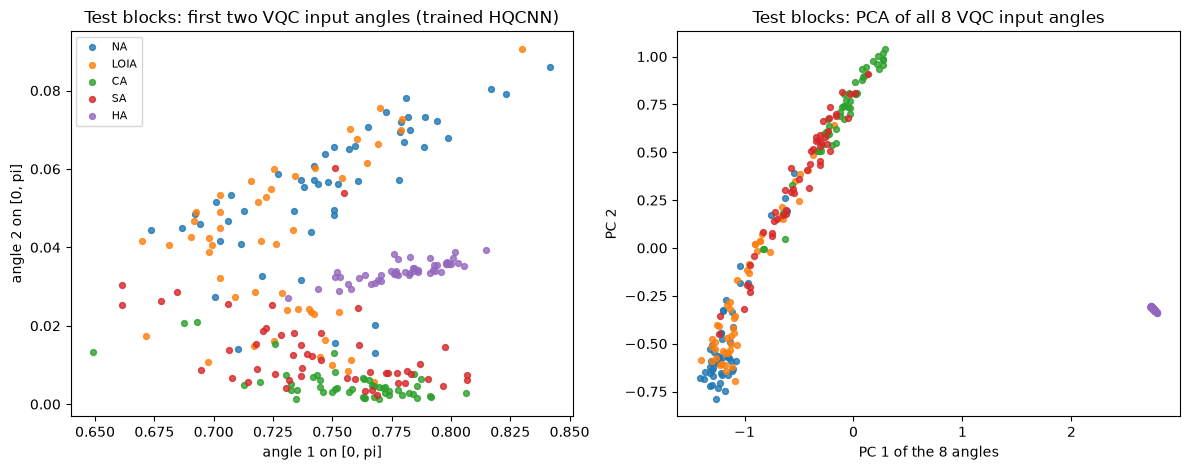

In [15]:
mh = RUNS[("HQCNN", s0)]["model"].eval()
with torch.no_grad(): ANG = torch.cat([mh.angles(Xte[i:i + 250]) for i in range(0, len(Xte), 250)]).numpy()
A01 = np.clip((ANG + np.pi) / 2, 0, np.pi)
P8 = PCA(2, random_state=SEED).fit(ANG).transform(ANG)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for k, c in enumerate(CLASSES):
    axes[0].scatter(A01[yte.numpy() == k, 0], A01[yte.numpy() == k, 1], s=18, color=pal(k), label=c, alpha=.8)
    axes[1].scatter(P8[yte.numpy() == k, 0], P8[yte.numpy() == k, 1], s=18, color=pal(k), label=c, alpha=.8)
axes[0].set_xlabel("angle 1 on [0, pi]"); axes[0].set_ylabel("angle 2 on [0, pi]"); axes[0].set_title("Test blocks: first two VQC input angles (trained HQCNN)")
axes[1].set_xlabel("PC 1 of the 8 angles"); axes[1].set_ylabel("PC 2"); axes[1].set_title("Test blocks: PCA of all 8 VQC input angles"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Qubit scaling (Fig. 3)

The paper trains HQCNNs with n = 4, 6, 8, 10 qubits (same recipe, same data) and compares the training-accuracy curves. We do
the same; the 8-qubit curve of the previous section is reused when the epoch budgets agree. For every n the circuit is a
different architecture (drawn in the "Quantum Circuit Architecture" section).

  4 qubits epoch   1/30: loss 1.626 | train acc 0.199 | val acc 0.200 | test acc 0.200 | 6 s


  4 qubits epoch   4/30: loss 1.310 | train acc 0.401 | val acc 0.400 | test acc 0.400 | 23 s


  4 qubits epoch   7/30: loss 1.158 | train acc 0.396 | val acc 0.400 | test acc 0.400 | 42 s


  4 qubits epoch  10/30: loss 1.129 | train acc 0.399 | val acc 0.400 | test acc 0.400 | 60 s


  4 qubits epoch  13/30: loss 1.121 | train acc 0.406 | val acc 0.400 | test acc 0.400 | 76 s


...

  10 qubits epoch  19/30: loss 0.928 | train acc 0.568 | val acc 0.620 | test acc 0.608 | 190 s


  10 qubits epoch  22/30: loss 0.904 | train acc 0.591 | val acc 0.627 | test acc 0.632 | 238 s


  10 qubits epoch  25/30: loss 0.846 | train acc 0.625 | val acc 0.640 | test acc 0.640 | 279 s


  10 qubits epoch  28/30: loss 0.816 | train acc 0.629 | val acc 0.640 | test acc 0.652 | 311 s


  10 qubits epoch  30/30: loss 0.837 | train acc 0.613 | val acc 0.667 | test acc 0.648 | 335 s


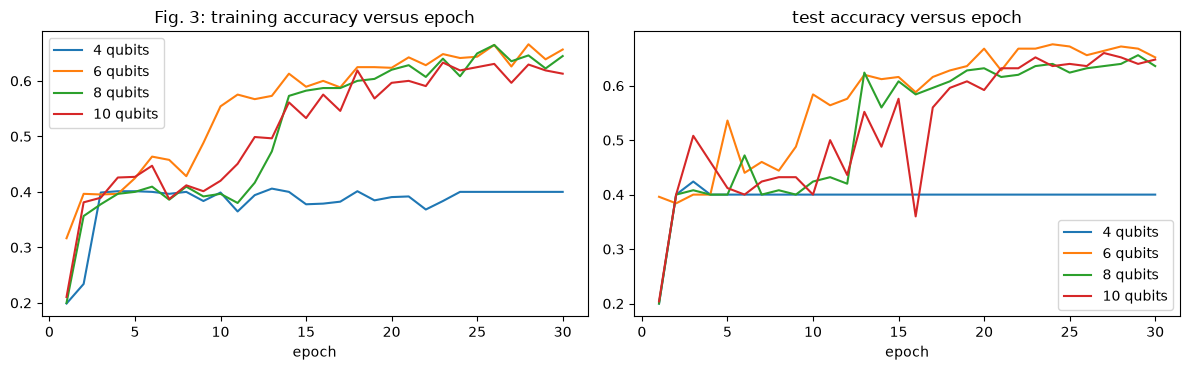

,VQC parameters,final train accuracy,best-val-epoch test accuracy,training time (s)
4,48.0,0.4000,0.424,162.7418
6,72.0,0.6565,0.668,211.4929
8,96.0,0.6447,0.620,238.8503
10,120.0,0.6129,0.648,335.1486


In [16]:
QSCAN = {}
for n in QUBIT_LIST:
    if n == N_QUBITS and QUBIT_EPOCHS == EPOCHS:
        QSCAN[n] = dict(H=RUNS[("HQCNN", SEED)]["H"], pred=RUNS[("HQCNN", SEED)]["pred"], params=nparams(RUNS[("HQCNN", SEED)]["model"], "core"), time=RUNS[("HQCNN", SEED)]["time"]); continue
    torch.manual_seed(SEED); m = HQCNN(n)
    H, be, tm = train_model(m, DATA, QUBIT_EPOCHS, SEED, tag=f"{n} qubits")
    QSCAN[n] = dict(H=H, pred=predict(m, Xte), params=nparams(m, "core"), time=tm)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for n in QUBIT_LIST:
    H = QSCAN[n]["H"]; ep = np.arange(1, len(H["loss"]) + 1)
    axes[0].plot(ep, H["train_acc"], label=f"{n} qubits"); axes[1].plot(ep, H["test_acc"], label=f"{n} qubits")
axes[0].set_title("Fig. 3: training accuracy versus epoch"); axes[1].set_title("test accuracy versus epoch")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()
QS = pd.DataFrame({n: {"VQC parameters": QSCAN[n]["params"], "final train accuracy": QSCAN[n]["H"]["train_acc"][-1], "best-val-epoch test accuracy": accuracy_score(yte.numpy(), QSCAN[n]["pred"]),
                       "training time (s)": QSCAN[n]["time"]} for n in QUBIT_LIST}).T
display(QS.round(4))

## 7. Parameter complexity (Sec. 5.5)

The paper compares the 96 parameters of the VQC with the parameters of classical layers. The arithmetic is checked below and
extended to the *whole* models, which the paper leaves out: the VQC is the small part of the HQCNN; the CNN in front of it holds
almost all the weights.

In [17]:
d, n = 32, N_QUBITS
N_FC = d * 2 ** n + 2 ** n
N_MLP = d * 128 + 128 * 128 + 128 * 5
print(f"single linear layer {d} -> 2^{n} = {2 ** n}: {N_FC:,} parameters (paper: 8448)")
print(f"MLP 32 -> 128 -> 128 -> 5 (weights only): {N_MLP:,} parameters (paper: about 21 000)")
print(f"VQC: {VQC_LAYERS} layers x {n} qubits x 3 angles = {VQC_LAYERS * n * 3} parameters (paper: 96)")
mh_, mr_ = RUNS[("HQCNN", s0)]["model"], RUNS[("ResNet", s0)]["model"]
PC = pd.DataFrame({"HQCNN": {"CNN extractor + transition": nparams(mh_, "extractor") + nparams(mh_, "to_q"), "VQC": nparams(mh_, "core"), "post-quantum layer": nparams(mh_, "head"), "total": nparams(mh_)},
                   "ResNet": {"CNN extractor + transition": nparams(mr_, "body"), "VQC": 0, "post-quantum layer": nparams(mr_, "fc"), "total": nparams(mr_)}})
display(PC)
print(f"the VQC is {100 * nparams(mh_, 'core') / nparams(mh_):.3f} % of the HQCNN's parameters; HQCNN / ResNet total = {nparams(mh_) / nparams(mr_):.2f}")

single linear layer 32 -> 2^8 = 256: 8,448 parameters (paper: 8448)
MLP 32 -> 128 -> 128 -> 5 (weights only): 21,120 parameters (paper: about 21 000)
VQC: 4 layers x 8 qubits x 3 angles = 96 parameters (paper: 96)


,HQCNN,ResNet
CNN extractor + transition,405480,1216640
VQC,96,0
post-quantum layer,45,1285
total,405621,1217925


the VQC is 0.024 % of the HQCNN's parameters; HQCNN / ResNet total = 0.33


## 8. Side by side with the paper, claim by claim

Verdict rule: "reproduced" if our value is within 2 accuracy points (0.02 on recall / F1) of the paper's, "not reached here"
if lower, "exceeded" if higher; "cannot be checked" if the quantity cannot be measured here. The paper's Table 1 is garbled
in the text we have: it reads NA recall 0.88 / LA recall 0.76 for the HQCNN, while the running text says the LOIA recall is
0.90; both are shown. The overall accuracy (0.93) is consistent with NA 0.88 + LOIA 0.76 and three perfect classes
((3 + 0.88 + 0.76) / 5 = 0.93).

In [18]:
def verdict(ours, paper, tol=0.02):
    if ours is None or np.isnan(ours): return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached here")

sh, sr, sc_c = summarize("HQCNN", s0), summarize("ResNet", s0), summarize("CNN + classical head", s0)
acc_h, acc_r = sh["overall"], sr["overall"]
rows = [
    ("HQCNN overall test accuracy", 0.93, acc_h, verdict(acc_h, 0.93)),
    ("ResNet overall test accuracy", 0.87, acc_r, verdict(acc_r, 0.87)),
    ("HQCNN minus ResNet accuracy gap (paper: +0.06)", 0.06, acc_h - acc_r, verdict(acc_h - acc_r, 0.06)),
    ("HQCNN recall CA (1.00)", 1.0, sh["recall"][2], verdict(sh["recall"][2], 1.0)),
    ("HQCNN recall SA (1.00)", 1.0, sh["recall"][3], verdict(sh["recall"][3], 1.0)),
    ("HQCNN recall HA (1.00)", 1.0, sh["recall"][4], verdict(sh["recall"][4], 1.0)),
    ("ResNet recall CA/SA/HA (1.00), minimum", 1.0, min(sr["recall"][2:]), verdict(min(sr["recall"][2:]), 1.0)),
    ("HQCNN recall LOIA (text 0.90 / table 0.76)", 0.90, sh["recall"][1], verdict(sh["recall"][1], 0.90)),
    ("HQCNN recall NA (table 0.88)", 0.88, sh["recall"][0], verdict(sh["recall"][0], 0.88)),
    ("ResNet recall NA (0.66)", 0.66, sr["recall"][0], verdict(sr["recall"][0], 0.66)),
    ("ResNet recall LOIA (0.66)", 0.66, sr["recall"][1], verdict(sr["recall"][1], 0.66)),
]
# qubit scaling claims
ns = list(QUBIT_LIST); fin = {n_: QSCAN[n_]["H"]["train_acc"][-1] for n_ in ns}; tst = {n_: accuracy_score(yte.numpy(), QSCAN[n_]["pred"]) for n_ in ns}
best_n = max(ns, key=lambda n_: tst[n_])
rows.append(("8 qubits best of the tested qubit numbers (test accuracy)", 8, best_n, "reproduced" if best_n == 8 else "not reached here"))
rows.append(("4 qubits reaches > 90 % training accuracy", 0.90, fin[4], "reproduced" if fin[4] > 0.90 else "not reached here"))
if 6 in fin: rows.append(("6 qubits reaches > 90 % training accuracy", 0.90, fin[6], "reproduced" if fin[6] > 0.90 else "not reached here"))
if 10 in fin: rows.append(("10 qubits reaches > 90 % training accuracy", 0.90, fin[10], "reproduced" if fin[10] > 0.90 else "not reached here"))
rows += [("VQC parameter count (96)", 96, nparams(mh_, "core"), "reproduced" if nparams(mh_, "core") == 96 else "not reached here"),
         ("single linear layer parameter count (8448)", 8448, N_FC, "reproduced" if N_FC == 8448 else "not reached here"),
         ("HQCNN has fewer parameters than the ResNet (ratio < 1)", 1.0, nparams(mh_) / nparams(mr_), "reproduced" if nparams(mh_) < nparams(mr_) else "not reached here")]
# where the errors are
off = sh["cm"].copy(); np.fill_diagonal(off, 0)
frac_na_loia = (off[0, 1] + off[1, 0]) / max(off.sum(), 1)
rows.append(("share of HQCNN errors that are NA <-> LOIA confusions (paper: essentially all, here: >= 0.9)", 1.0, frac_na_loia, "cannot be checked" if off.sum() == 0 else ("reproduced" if frac_na_loia >= 0.9 else "not reached here")))
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
display(CMP.round(4))
print("\nreference points on the same blocks: random forest on window features:", round(accuracy_score(yte.numpy(), REF["RandomForest on 8 window features"]), 4),
      "| SVC rbf:", round(accuracy_score(yte.numpy(), REF["SVC (rbf) on 8 window features"]), 4), "| variance-only ceiling:", round(CEILING, 4),
      "| CNN + classical head:", round(sc_c["overall"], 4))
print("verdict counts:", CMP["verdict"].value_counts().to_dict(), "| total run time:", f"{(time.time() - T0) / 60:.1f} min")

,claim,paper,this notebook,verdict
0,HQCNN overall test accuracy,0.93,0.6200,not reached here
1,ResNet overall test accuracy,0.87,0.8200,not reached here
2,HQCNN minus ResNet accuracy gap (paper: +0.06),0.06,-0.2000,not reached here
3,HQCNN recall CA (1.00),1.00,0.9000,not reached here
4,HQCNN recall SA (1.00),1.00,0.2600,not reached here
5,HQCNN recall HA (1.00),1.00,1.0000,reproduced
6,"ResNet recall CA/SA/HA (1.00), minimum",1.00,0.9200,not reached here
7,HQCNN recall LOIA (text 0.90 / table 0.76),0.90,0.0200,not reached here
8,HQCNN recall NA (table 0.88),0.88,0.9200,exceeded
9,ResNet recall NA (0.66),0.66,0.7000,exceeded



reference points on the same blocks: random forest on window features: 0.848 | SVC rbf: 0.84 | variance-only ceiling: 0.86 | CNN + classical head: 0.68
verdict counts: {'not reached here': 13, 'reproduced': 4, 'exceeded': 2} | total run time: 27.4 min


## What this run shows (committed run: `FAST_MODE = False`, Q = 2500, 250 blocks per class, 30 epochs, one model seed)

* **The pipeline works; the paper's headline numbers are not reproduced.** The HQCNN reaches an overall test accuracy of about 0.62 (paper 0.93), the ResNet about 0.82 (paper 0.87), the same CNN with a classical head about 0.68. The hybrid model is **not** better than the ResNet here (paper: +6 points); the gap is about -20 points in this run.
* **Calibration, saturation and hybrid attacks:** the hybrid attack is detected perfectly by all three networks; calibration and saturation are detected well by the ResNet (recall about 0.9) but only partly by the HQCNN (the saturation recall of the HQCNN is the weakest entry). In the paper all three are perfect for both models.
* **NA versus LOIA** is the hard pair, as in the paper, but our blocks have only 2500 pulses, so even the best possible variance-only decision is limited (about 0.86 overall, measured in section 3). The HQCNN of this run collapses LOIA into NA (LOIA recall close to 0) while the ResNet recovers about half of the LOIA blocks.
* **Qubit scaling (Fig. 3):** with the same short budget the curves of 6, 8 and 10 qubits are within the run-to-run noise of each other and the 4-qubit model barely learns in the budget; "8 qubits is best" is therefore not supported or contradicted by this run. Nothing here exceeds 90 % training accuracy.
* **How much of this is the budget and the seed?** An earlier exploratory run of the same notebook with 200 blocks per class and 20 epochs gave 0.71 (HQCNN), 0.77 (ResNet) and 0.73 (CNN + classical head); the HQCNN accuracy moves by about 10 points between two runs of a one-seed, 30-epoch experiment. The paper trains for 100 epochs on 4000 blocks of 10 000 pulses with learning rates of 1e-4 and 1e-3; we train for 30 epochs on 1000 blocks of 2500 pulses. A plain 4-layer CNN with a 8-number bottleneck learns the subtle statistics slowly, and the residual network learns them faster. Only a run at `PAPER_SCALE` (or several seeds) can settle whether the paper's ranking would appear on this simulator; it was not feasible on this machine (a three-seed version of this notebook did not finish within two hours on the shared CPU).
* **Hand-made statistics are strong:** a random forest on eight block statistics gets about 0.85, above every network here.

## 9. Reading the paper critically

* **The data are the experiment.** The reported 93 % and the 6-point gap come from a private simulated dataset whose attack
  strengths are "fixed representative values". How hard NA versus LOIA is depends entirely on the LOIA scaling k and the block
  length; with a few percent change in k the accuracy of *any* model moves from chance to 100 %. The calculation of the
  variance-only ceiling above shows how much of the 5-class accuracy is simply decided by that one number. Our dataset follows
  the paper's equations but with our own k, so agreement or disagreement with 0.93 says little about the quantum circuit.
* **Model selection on the test set.** "Best Model Saving" keeps the weights of the epoch with the highest *test* accuracy. For a
  1000-block test set and 100 epochs this adds an optimistic bias of a few points to every curve, and it is applied to both models;
  the table above shows the honest (validation-selected) number next to the paper-style one.
* **A single split and no confidence interval.** One run of 1000 test blocks has a binomial standard error of about one accuracy
  point, and the NA/LOIA recalls rest on about 200 blocks each. A 6-point gap is probably real for that dataset, but the paper gives no
  seeds, no spread and no ResNet hyper-parameters.
* **What the quantum circuit contributes.** The VQC receives 8 numbers; everything that needs to be found in the 10 000 pulses is
  found by the CNN. The "CNN + classical head" ablation (not in the paper) replaces the VQC by 72 classical weights and shows
  whether the quantum part matters on this task. "96 parameters instead of 21 000" compares one layer of a model with the
  whole of another: the HQCNN still contains a CNN with hundreds of thousands of weights. Parameter efficiency should be measured end to end.
* **Pulses are independent.** In the physical model the pulses of a block are i.i.d., so reshaping to 100 x 100 creates no spatial
  structure; the CNN is a (learned) computation of block statistics. A classifier on eight hand-made statistics is a strong reference
  (see section 3) and a fair classical baseline for the *task*, not just the architecture.
* **No hardware, no noise.** All results are exact simulations of an 8-qubit circuit. The claims about "near real-time" inference
  and robustness against adversarial inputs (Sec. 5.6) are arguments, not experiments.
* **Equation 5 and Table 1** are ambiguous in the extracted text (calibration variance; which row of Table 1 holds which metric);
  we state our reading above.

## 10. Exercises

1. Change `K_LOIA` to 0.93 and to 0.99 (and regenerate the data). How does the NA-versus-LOIA accuracy of the HQCNN, the ResNet and
   the variance threshold change? At which k does each model fail?
2. Replace the random-pulse-order augmentation by no augmentation (`train_model`) and compare the learning curves and the gap
   between training and test accuracy.
3. Train the HQCNN with n = 3 and n = 12 qubits (the 12-qubit simulator needs more memory: use `FastVQC` with a small batch). Is there
   an optimal number of qubits, or is the "8 qubits is best" result of Fig. 3 within the run-to-run noise? Repeat with five seeds.
4. Remove the data re-uploading (encode once at the beginning, 4 variational layers after it) by editing `FastVQC.forward` and
   `make_qnode`, check the equivalence cell again, and measure the accuracy.
5. Add the paper's `StronglyEntanglingLayers` noise robustness question: simulate readout noise by adding Gaussian noise of standard
   deviation 0.05 to the eight expectation values before the post-quantum layer, at test time only, and compare HQCNN, CNN + classical
   head and ResNet (the ResNet has no quantum read-out: add the same noise to its penultimate features).